# Task 1

In [53]:
import pandas as pd

df = pd.read_csv("pima-indians-diabetes.csv")
display(df.head(3))

,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0


In [54]:
df.columns.tolist()

['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1']

In [55]:
column_names = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

In [56]:
df = pd.read_csv("pima-indians-diabetes.csv",header=None,names=column_names)
df.head(3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1


In [57]:
class_count = df["Outcome"].value_counts()
class_prob = df["Outcome"].value_counts(normalize=True)
print("class_count: ",class_count)
print("class_prob: ",class_prob)

class_count:  Outcome
0    500
1    268
Name: count, dtype: int64
class_prob:  Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


In [58]:
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = (df[invalid_zero_cols] == 0).sum()
zero_props = (df[invalid_zero_cols] == 0).mean()
print("zero_counts:\n",zero_counts)
print("zero_props:\n",zero_props)

zero_counts:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
zero_props:
 Glucose          0.006510
BloodPressure    0.045573
SkinThickness    0.295573
Insulin          0.486979
BMI              0.014323
dtype: float64


In [59]:
import numpy as np
features = ["Glucose","BMI"]
x = df[features]
y = df["Outcome"]
x.replace({col: {0: np.nan} for col in features},inplace=True)

,Glucose,BMI
0,148.0,33.6
1,85.0,26.6
2,183.0,23.3
3,89.0,28.1
4,137.0,43.1
...,...,...
763,101.0,32.9
764,122.0,36.8
765,121.0,26.2
766,126.0,30.1


In [60]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.8,stratify=y,random_state=42)

In [61]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),("scaler",StandardScaler())
])
x_train_scaled = pipeline.fit_transform(x_train)
x_test_scaled = pipeline.transform(x_test)

We fit the imputer and scaler on the training data only, so they learn the median, mean, and standard deviation from it. The test data is only transformed using these values, so no information from the test set leaks into training. If leakage occurs, the models' test results may look better than their actual performance, making the comparison unfair.

# Task 2

In [62]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
x_train_np = np.asarray(x_train_scaled)
x_test_np = np.asarray(x_test_scaled)
y_train_np = np.asarray(y_train)
y_test_np = np.asarray(y_test)

In [64]:
class perceptron:
    def __init__(self,learning_rate = 0.01, max_epochs = 200):
        self.lr = learning_rate
        self.max_epochs = max_epochs
        self.weights = None
        self.bias = 0.0

    def fit(self,x,y):
        n_samples, n_features = x.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        for epoch in range(self.max_epochs):
            mistakes = 0
            for i in range(n_samples):
                linear_output = np.dot(x[i],self.weights)+self.bias
                y_preds = 1 if linear_output >= 0.0 else 0
                error = y[i] - y_preds
                if error != 0:
                    self.weights += self.weights * error * x[i]
                    self.bias += self.bias * error
                    mistakes += 1
            if mistakes == 0:
                print(f"Perceptron converged to 0 error with at epoch {epoch + 1}")
                break

    def predict(self,x):
        linear_output = np.dot(x,self.weights) + self.bias
        return (linear_output >= 0.0).astype(int)

In [65]:
class LogisticReg:
    def __init__(self,learning_rate = 0.1,max_epochs = 200, tol=1e-6):
        self.lr = learning_rate
        self.max_epochs = max_epochs
        self.tol = tol
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def _sigmoid(self, z):
        z_clipped = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z_clipped))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for epoch in range(self.max_epochs):
            z = np.dot(X, self.weights) + self.bias
            y_prob = self._sigmoid(z)
            eps = 1e-15
            prob_clipped = np.clip(y_prob, eps, 1 - eps)
            loss = -np.mean(y * np.log(prob_clipped) + (1 - y) * np.log(1 - prob_clipped))
            self.loss_history.append(loss)
            if epoch > 0 and abs(self.loss_history[-2] - loss) < self.tol:
                print(f"Logistic Regression converged at epoch {epoch + 1}")
                break

            dw = (1 / n_samples) * np.dot(X.T, (y_prob - y))
            db = (1 / n_samples) * np.sum(y_prob - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self._sigmoid(z)

    def predict(self, X):
        return np.where(self.predict_proba(X) >= 0.5, 1, 0)

    

In [ ]:
perceptron = perceptron(learning_rate=0.01, max_epochs=200)
perceptron.fit(x_train_np, y_train_np)

print("Perceptron Learned Weights (Glucose, BMI):", perceptron.weights)
print("Perceptron Learned Bias:", perceptron.bias)
print("Perceptron First 5 Test Predictions:", perceptron.predict(x_test_np)[:5])

Perceptron Learned Weights (Glucose, BMI): [0. 0.]
Perceptron Learned Bias: 0.0
Perceptron First 5 Test Predictions: [1 1 1 1 1]


In [ ]:
log_reg = LogisticReg(learning_rate=0.1, max_epochs=1000, tol=1e-6)
log_reg.fit(x_train_np, y_train_np)

print("Logistic Regression Learned Weights (Glucose, BMI):", log_reg.weights)
print("Logistic Regression Learned Bias:", log_reg.bias)
print("Logistic Regression First 5 Test Predictions:", log_reg.predict(x_test_np)[:5])
print("Logistic Regression First 5 Test Probabilities:", np.round(log_reg.predict_proba(x_test_np)[:5], 4))

Logistic Regression converged at epoch 334
Logistic Regression Learned Weights (Glucose, BMI): [1.06631459 0.87984165]
Logistic Regression Learned Bias: -0.8247671946327796
Logistic Regression First 5 Test Predictions: [0 0 0 1 1]
Logistic Regression First 5 Test Probabilities: [0.0698 0.3481 0.1858 0.6032 0.8393]


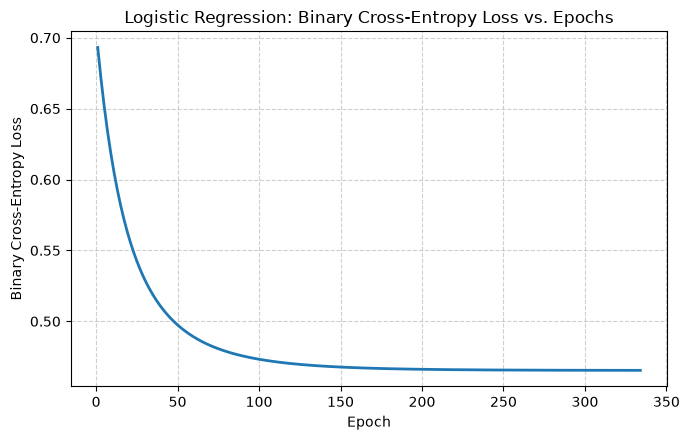

In [68]:
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, len(log_reg.loss_history) + 1), log_reg.loss_history, color='#1f77b4', lw=2)
plt.title("Logistic Regression: Binary Cross-Entropy Loss vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Task 3

In [69]:
from sklearn.linear_model import Perceptron, LogisticRegression

In [70]:
sklearn_perceptron = Perceptron(max_iter=1000, random_state=42)
sklearn_perceptron.fit(x_train_np, y_train_np)

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [71]:
sklearn_logreg = LogisticRegression(random_state=42)
sklearn_logreg.fit(x_train_np, y_train_np)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [72]:
print("--- Learned Coefficients (w1: Glucose, w2: BMI, b: Intercept) ---")
print(f"Scratch Perceptron:     w = {perceptron.weights}, b = {perceptron.bias:.4f}")
print(f"Sklearn Perceptron:     w = {sklearn_perceptron.coef_[0]}, b = {sklearn_perceptron.intercept_[0]:.4f}")
print(f"Scratch LogReg:         w = {log_reg.weights}, b = {log_reg.bias:.4f}")
print(f"Sklearn LogReg:         w = {sklearn_logreg.coef_[0]}, b = {sklearn_logreg.intercept_[0]:.4f}")

--- Learned Coefficients (w1: Glucose, w2: BMI, b: Intercept) ---
Scratch Perceptron:     w = [0. 0.], b = 0.0000
Sklearn Perceptron:     w = [3.12942214 0.58757417], b = -1.0000
Scratch LogReg:         w = [1.06631459 0.87984165], b = -0.8248
Sklearn LogReg:         w = [1.02830089 0.84883349], b = -0.8258


In [73]:
models = [
    ("Perceptron (Scratch)", perceptron.weights, perceptron.bias),
    ("Perceptron (Scikit-Learn)", sklearn_perceptron.coef_[0], sklearn_perceptron.intercept_[0]),
    ("Logistic Regression (Scratch)", log_reg.weights, log_reg.bias),
    ("Logistic Regression (Scikit-Learn)", sklearn_logreg.coef_[0], sklearn_logreg.intercept_[0])
]
models

[('Perceptron (Scratch)', array([0., 0.]), np.float64(0.0)),
 ('Perceptron (Scikit-Learn)',
  array([3.12942214, 0.58757417]),
  np.float64(-1.0)),
 ('Logistic Regression (Scratch)',
  array([1.06631459, 0.87984165]),
  np.float64(-0.8247671946327796)),
 ('Logistic Regression (Scikit-Learn)',
  array([1.02830089, 0.84883349]),
  np.float64(-0.825770868889891))]

C:\Users\Abdullah\AppData\Local\Temp\ipykernel_16756\4239158809.py:2: RuntimeWarning: invalid value encountered in divide
  return -(w[0] * x_vals + b) / w[1]


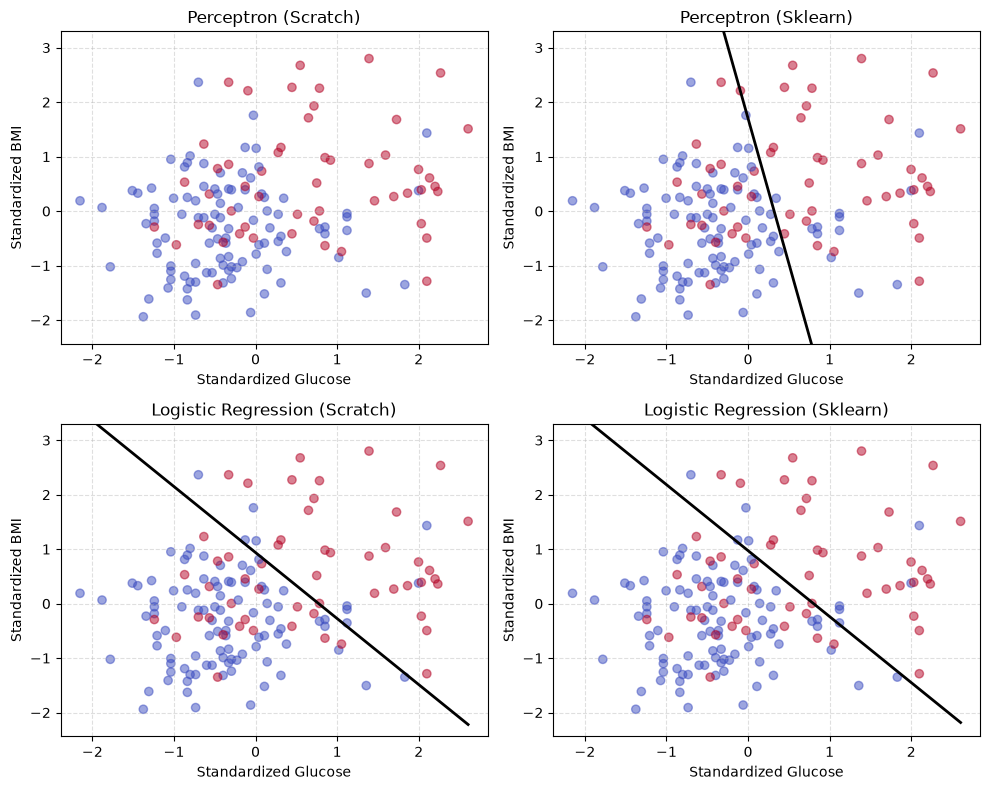

In [74]:
def get_boundary_line(w, b, x_vals):
    return -(w[0] * x_vals + b) / w[1]

x_vals = np.linspace(x_train_np[:, 0].min(), x_train_np[:, 0].max(), 100)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# 1. Scratch Perceptron
axes[0, 0].scatter(x_train_np[:, 0], x_train_np[:, 1], c=y_train_np, cmap='coolwarm', alpha=0.5)
axes[0, 0].plot(x_vals, get_boundary_line(perceptron.weights, perceptron.bias, x_vals), 'k-', lw=2)
axes[0, 0].set_title("Perceptron (Scratch)")

# 2. Sklearn Perceptron
axes[0, 1].scatter(x_train_np[:, 0], x_train_np[:, 1], c=y_train_np, cmap='coolwarm', alpha=0.5)
axes[0, 1].plot(x_vals, get_boundary_line(sklearn_perceptron.coef_[0], sklearn_perceptron.intercept_[0], x_vals), 'k-', lw=2)
axes[0, 1].set_title("Perceptron (Sklearn)")

# 3. Scratch Logistic Regression
axes[1, 0].scatter(x_train_np[:, 0], x_train_np[:, 1], c=y_train_np, cmap='coolwarm', alpha=0.5)
axes[1, 0].plot(x_vals, get_boundary_line(log_reg.weights, log_reg.bias, x_vals), 'k-', lw=2)
axes[1, 0].set_title("Logistic Regression (Scratch)")

# 4. Sklearn Logistic Regression
axes[1, 1].scatter(x_train_np[:, 0], x_train_np[:, 1], c=y_train_np, cmap='coolwarm', alpha=0.5)
axes[1, 1].plot(x_vals, get_boundary_line(sklearn_logreg.coef_[0], sklearn_logreg.intercept_[0], x_vals), 'k-', lw=2)
axes[1, 1].set_title("Logistic Regression (Sklearn)")

# Keep labels and y-limits consistent across all subplots
y_min, y_max = x_train_np[:, 1].min() - 0.5, x_train_np[:, 1].max() + 0.5
for ax in axes.flat:
    ax.set_xlabel("Standardized Glucose")
    ax.set_ylabel("Standardized BMI")
    ax.set_ylim(y_min, y_max)
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Task 4

In [75]:
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,f1_score)

In [76]:
def calculate_metrics_manual(y_true, y_pred):
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))

    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0

    return {
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1
    }

In [ ]:
predictions = {
    'Perceptron (Scratch)': perceptron.predict(x_test_np),
    'Perceptron (Sklearn)': sklearn_perceptron.predict(x_test_np),
    'Logistic Regression (Scratch)': log_reg.predict(x_test_np),
    'Logistic Regression (Sklearn)': sklearn_logreg.predict(x_test_np)
}

In [78]:
sample_pred = predictions['Logistic Regression (Scratch)']
man = calculate_metrics_manual(y_test_np, sample_pred)

In [79]:
print("Manual vs. Scikit-Learn Verification (Logistic Regression - Scratch):")
print(f"Accuracy:  Manual = {man['Accuracy']:.4f} | Sklearn = {accuracy_score(y_test_np, sample_pred):.4f}")
print(f"Precision: Manual = {man['Precision']:.4f} | Sklearn = {precision_score(y_test_np, sample_pred):.4f}")
print(f"Recall:    Manual = {man['Recall']:.4f} | Sklearn = {recall_score(y_test_np, sample_pred):.4f}")
print(f"F1 Score:  Manual = {man['F1']:.4f} | Sklearn = {f1_score(y_test_np, sample_pred):.4f}")
print("Confusion Matrix (Manual):\n", np.array([[man['TN'], man['FP']], [man['FN'], man['TP']]]))
print("Confusion Matrix (Sklearn):\n", confusion_matrix(y_test_np, sample_pred))

Manual vs. Scikit-Learn Verification (Logistic Regression - Scratch):
Accuracy:  Manual = 0.7447 | Sklearn = 0.7447
Precision: Manual = 0.6495 | Sklearn = 0.6495
Recall:    Manual = 0.5860 | Sklearn = 0.5860
F1 Score:  Manual = 0.6161 | Sklearn = 0.6161
Confusion Matrix (Manual):
 [[332  68]
 [ 89 126]]
Confusion Matrix (Sklearn):
 [[332  68]
 [ 89 126]]


In [80]:
results = []
for name, y_pred in predictions.items():
    metrics = calculate_metrics_manual(y_test_np, y_pred)
    results.append({
        'Model': name,
        'TN': metrics['TN'],
        'FP': metrics['FP'],
        'FN': metrics['FN'],
        'TP': metrics['TP'],
        'Accuracy': round(metrics['Accuracy'], 3),
        'Precision': round(metrics['Precision'], 3),
        'Recall': round(metrics['Recall'], 3),
        'F1 Score': round(metrics['F1'], 3)
    })

In [81]:
comparison_df = pd.DataFrame(results)
print("\nModel Evaluation Comparison Table:")
print(comparison_df.to_string(index=False))


Model Evaluation Comparison Table:
                        Model  TN  FP  FN  TP  Accuracy  Precision  Recall  F1 Score
         Perceptron (Scratch)   0 400   0 215     0.350      0.350   1.000     0.518
         Perceptron (Sklearn) 312  88  76 139     0.733      0.612   0.647     0.629
Logistic Regression (Scratch) 332  68  89 126     0.745      0.649   0.586     0.616
Logistic Regression (Sklearn) 336  64  92 123     0.746      0.658   0.572     0.612


In [ ]:
predictions = {
    'Perceptron (Scratch)': perceptron.predict(x_test_np),
    'Perceptron (Sklearn)': sklearn_perceptron.predict(x_test_np),
    'Logistic Regression (Scratch)': log_reg.predict(x_test_np),
    'Logistic Regression (Sklearn)': sklearn_logreg.predict(x_test_np)
}

# Evaluate every model against y_test_np
results = []
for name, y_pred in predictions.items():
    metrics = calculate_metrics_manual(y_test_np, y_pred)
    results.append({
        'Model': name,
        'TN': metrics['TN'],
        'FP': metrics['FP'],
        'FN': metrics['FN'],
        'TP': metrics['TP'],
        'Accuracy': round(metrics['Accuracy'], 3),
        'Precision': round(metrics['Precision'], 3),
        'Recall': round(metrics['Recall'], 3),
        'F1 Score': round(metrics['F1'], 3)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

                        Model  TN  FP  FN  TP  Accuracy  Precision  Recall  F1 Score
         Perceptron (Scratch)   0 400   0 215     0.350      0.350   1.000     0.518
         Perceptron (Sklearn) 312  88  76 139     0.733      0.612   0.647     0.629
Logistic Regression (Scratch) 332  68  89 126     0.745      0.649   0.586     0.616
Logistic Regression (Sklearn) 336  64  92 123     0.746      0.658   0.572     0.612
